# Zeitreihen vorhersagen mit ARMA, ARIMA und SARIMA

Wir erzeugen sechs künstliche Zeitreihen und prognostizieren jeweils die letzten vier Wochen aus den vorherigen 24 Wochen. Für **jede Zeitreihe** vergleichen wir acht Modellspezifikationen aus allen drei Modellfamilien. Die wahre Zukunft bleibt beim Fit verborgen.

**Lernziele:** Stationarität, Trend und Saisonalität unterscheiden; die Parameter der Modelle verstehen; Forecasts mit Unsicherheit darstellen; die Güte an zeitlich späteren Daten messen.

## 1. Welche Python-Bibliothek?

| Bibliothek | Einfacher Einstieg | Besonders geeignet für |
|---|---|---|
| **statsmodels** | `ARIMA(y, order=..., seasonal_order=...).fit()` | Explizite ARMA-/ARIMA-/SARIMA-Modelle, statistische Auswertung und Prognoseintervalle |
| **pmdarima** | `auto_arima(y, seasonal=True, m=7)` | Automatisierte Suche nach Modellordnungen mit begrenztem Suchraum |
| **StatsForecast** | `AutoARIMA(season_length=7)` | Automatische Modelle und Verarbeitung vieler Zeitreihen |

**Empfehlung für dieses Notebook: statsmodels.** Wir setzen die Modellordnungen bewusst selbst, damit die Unterschiede sichtbar bleiben. Ein ARMA-Modell ist dabei ein ARIMA-Modell mit `d=0`; SARIMA verwendet zusätzlich `seasonal_order`. Eine separate, veraltete ARMA-Klasse brauchen wir nicht.

Offizielle Quellen: [statsmodels ARIMA](https://www.statsmodels.org/stable/generated/statsmodels.tsa.arima.model.ARIMA.html), [pmdarima auto_arima](https://alkaline-ml.com/pmdarima/modules/generated/pmdarima.arima.auto_arima.html), [StatsForecast](https://github.com/Nixtla/statsforecast).

### Installation und Ausführung

Falls Pakete fehlen, die folgende Installationszeile einkommentieren und ausführen. Anschließend bei Bedarf den Kernel neu starten und **alle Zellen von oben nach unten** ausführen. Es werden keine externen Daten benötigt. Die installierten Versionen werden für die Reproduzierbarkeit ausgegeben.

In [1]:
# %pip install numpy pandas matplotlib statsmodels

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels
from IPython.display import display, Markdown
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.arima_process import arma_generate_sample

plt.rcParams.update({"figure.figsize": (13, 4), "axes.grid": True,
                     "grid.alpha": 0.25, "font.size": 10})
print(f"NumPy {np.__version__} | pandas {pd.__version__} | statsmodels {statsmodels.__version__}")

NumPy 2.5.1 | pandas 3.0.5 | statsmodels 0.14.6


## 2. Was bedeuten die Modellparameter?

- **ARMA(p, q):** Vergangene Werte (AR, Ordnung `p`) und vergangene Innovationsfehler (MA, Ordnung `q`) erklären die aktuelle Abweichung vom Mittelwert. Der MA-Teil ist kein gleitender Durchschnitt der Messwerte. Das Modell setzt eine stationäre Reihe voraus.
- **ARIMA(p, d, q):** Vor dem ARMA-Teil wird `d`-mal differenziert. Bei `d=1` modellieren wir die Änderungen $y_t-y_{t-1}$. Die Prognose wird automatisch auf die ursprüngliche Skala zurückgerechnet.
- **SARIMA(p, d, q)(P, D, Q, s):** Zusätzliche saisonale AR-/MA-Terme sowie saisonale Differenzierung. Bei `D=1` und `s=7` werden Differenzen $y_t-y_{t-7}$ verwendet.

**Stationär** bedeutet hier schwach stationär: konstanter Erwartungswert, konstante Varianz und eine Kovarianz, die nur vom Zeitabstand abhängt. Ein deterministischer Trend oder eine feste saisonale Mittelwertkurve verletzt diese Voraussetzung. Saisonale Abhängigkeiten können dagegen auch in einem stationären Prozess vorkommen.

`trend="c"` schätzt eine Konstante, `trend="t"` einen linearen Zeittrend und `trend="n"` keinen deterministischen Trend. In statsmodels wirkt ein linearer Zeittrend bei `d=1` als Drift. Bei `d=0` bezeichnet `"ct"` Konstante plus linearen Trend.

## 3. Sechs Zeitreihen erzeugen

Alle Beobachtungen liegen täglich vor, die saisonale Periode beträgt sieben Tage. Die Zufallszahlen sind durch einen festen Seed reproduzierbar. Stationäre Prozesse starten nach einer Aufwärmphase (Burn-in).

| Reihe | Konstruktion | Stationär? | Trend | Saisonaler Charakter |
|---|---|---|---|---|
| A | ARMA(1,1) um Niveau 20 | Ja | Nein | Keiner |
| B | Linearer Trend + stationärer ARMA-Fehler | Nein, trendstationär | Deterministisch | Keiner |
| C | Random Walk | Nein, differenzstationär | Kein deterministischer Trend; zufällige Wanderung | Keiner |
| D | Feste Wochenkurve + stationärer Fehler | Nein, periodischer Mittelwert | Nein | Deterministisches Wochenmuster |
| E | Linearer Trend + Wochenkurve + Fehler | Nein | Deterministisch | Deterministisches Wochenmuster |
| F | Saisonaler AR-Prozess $x_t=0{,}75x_{t-7}+\varepsilon_t$ | Ja | Nein | Stationäre Abhängigkeit bei Lag 7 |

Die Zuordnung ist aus der Konstruktion bekannt. Ein einzelner Verlauf kann täuschen: Ein Random Walk kann zum Beispiel wie ein Trend aussehen. Hier geht es um den datenerzeugenden Prozess, nicht um eine Klassifikation allein nach Augenschein.

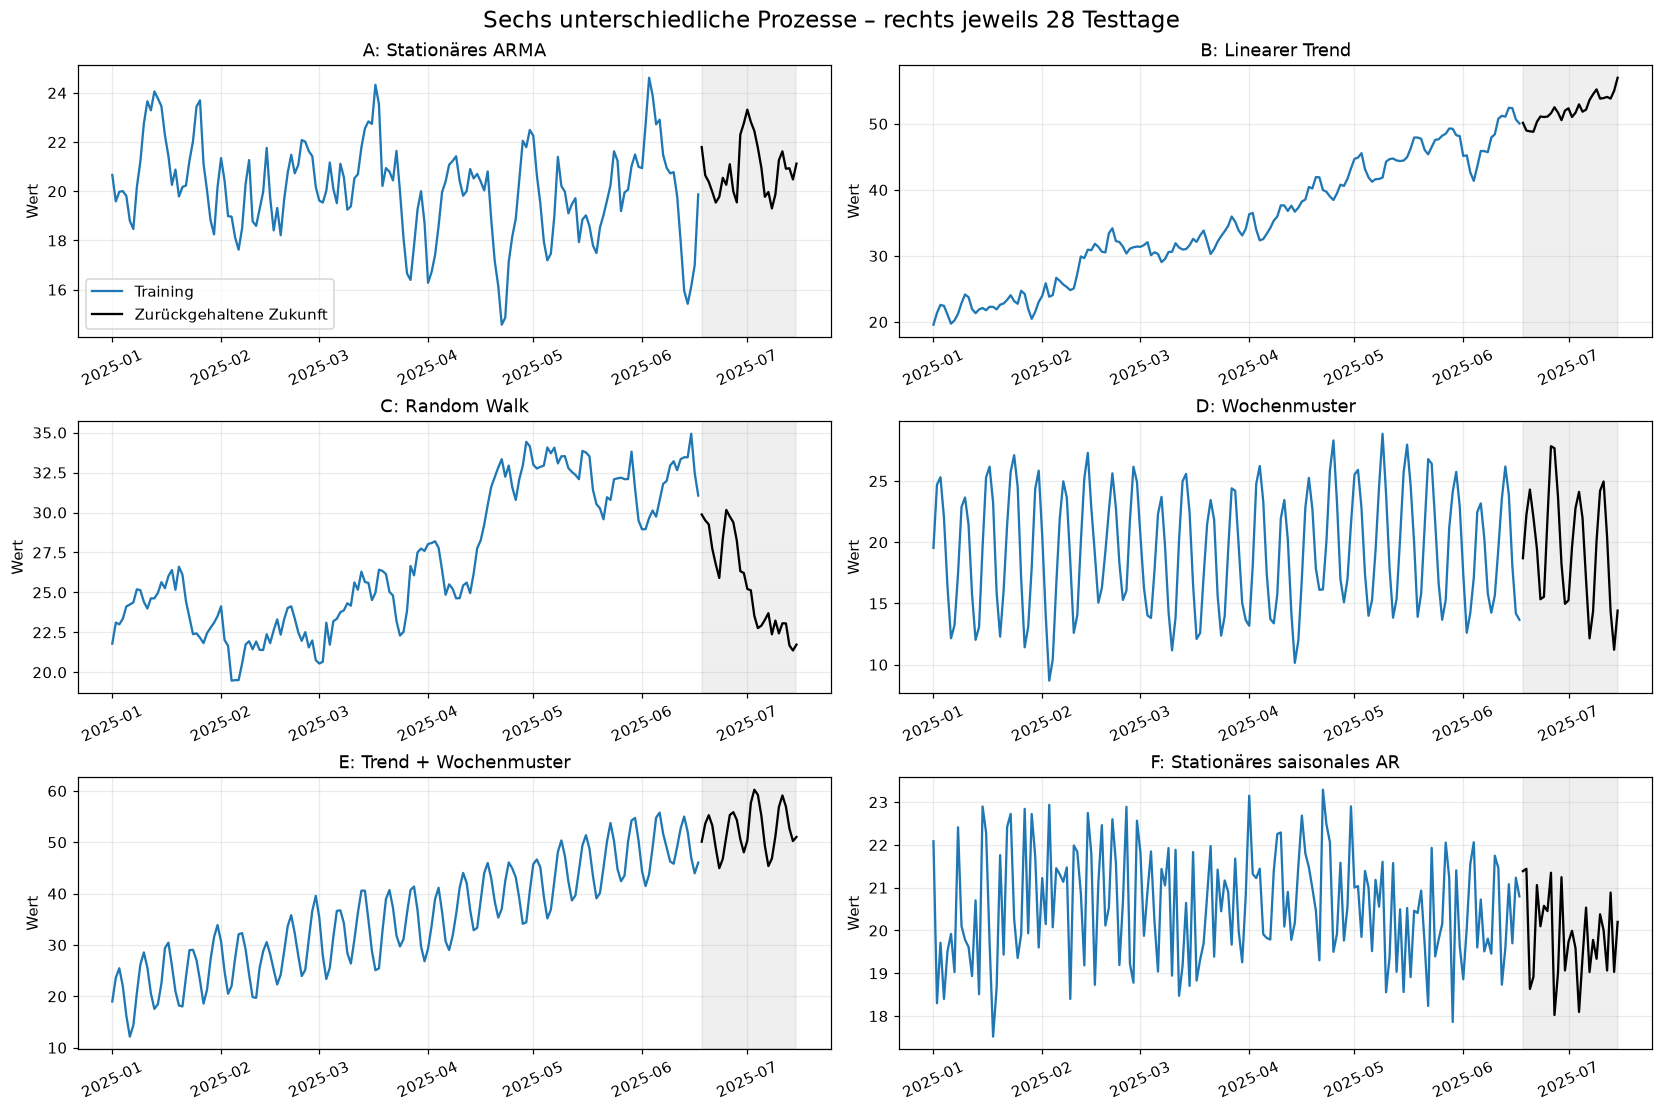

In [2]:
SEED = 42
N_TRAIN = 168
HORIZONT = 28
PERIODE = 7
N = N_TRAIN + HORIZONT
rng = np.random.default_rng(SEED)
t = np.arange(N)
index = pd.date_range("2025-01-01", periods=N, freq="D")

def arma_fehler():
    # statsmodels erwartet das AR-Polynom 1 - phi*L.
    return arma_generate_sample(ar=[1, -0.65], ma=[1, 0.4], nsample=N,
                                burnin=300, distrvs=rng.standard_normal)

wochenkurve = 6 * np.sin(2 * np.pi * t / PERIODE)
saison_ar = np.r_[1.0, np.zeros(PERIODE - 1), -0.75]
reihen = {
    "A: Stationäres ARMA": pd.Series(20 + arma_fehler(), index=index),
    "B: Linearer Trend": pd.Series(20 + 0.18 * t + arma_fehler(), index=index),
    "C: Random Walk": pd.Series(20 + np.cumsum(rng.normal(size=N)), index=index),
    "D: Wochenmuster": pd.Series(20 + wochenkurve + arma_fehler(), index=index),
    "E: Trend + Wochenmuster": pd.Series(20 + 0.18 * t + wochenkurve + arma_fehler(), index=index),
    "F: Stationäres saisonales AR": pd.Series(
        20 + arma_generate_sample(ar=saison_ar, ma=[1], nsample=N,
                                  burnin=300, distrvs=rng.standard_normal), index=index),
}
splits = {name: (y.iloc[:N_TRAIN], y.iloc[N_TRAIN:]) for name, y in reihen.items()}

fig, axes = plt.subplots(3, 2, figsize=(15, 10), constrained_layout=True)
for ax, (name, (train, test)) in zip(axes.flat, splits.items()):
    ax.plot(train.index, train, label="Training", color="tab:blue")
    ax.plot(test.index, test, label="Zurückgehaltene Zukunft", color="black")
    ax.axvspan(test.index[0], test.index[-1], color="gray", alpha=0.12)
    ax.set_title(name)
    ax.set_ylabel("Wert")
    ax.tick_params(axis="x", rotation=25)
axes.flat[0].legend()
fig.suptitle("Sechs unterschiedliche Prozesse – rechts jeweils 28 Testtage", fontsize=15)
plt.show()

### Differenzieren: Was ändert sich?

Ein einfacher Unterschied entfernt einen linearen Trend und macht den Random Walk stationär. Ein saisonaler Unterschied entfernt die feste Wochenkurve; bei Trend plus Wochenkurve bleibt danach ein konstanter mittlerer Zuwachs. Das bedeutet nicht, dass jede Reihe differenziert werden sollte: Eine bereits stationäre Reihe kann durch unnötige Differenzierung schwerer zu modellieren werden.

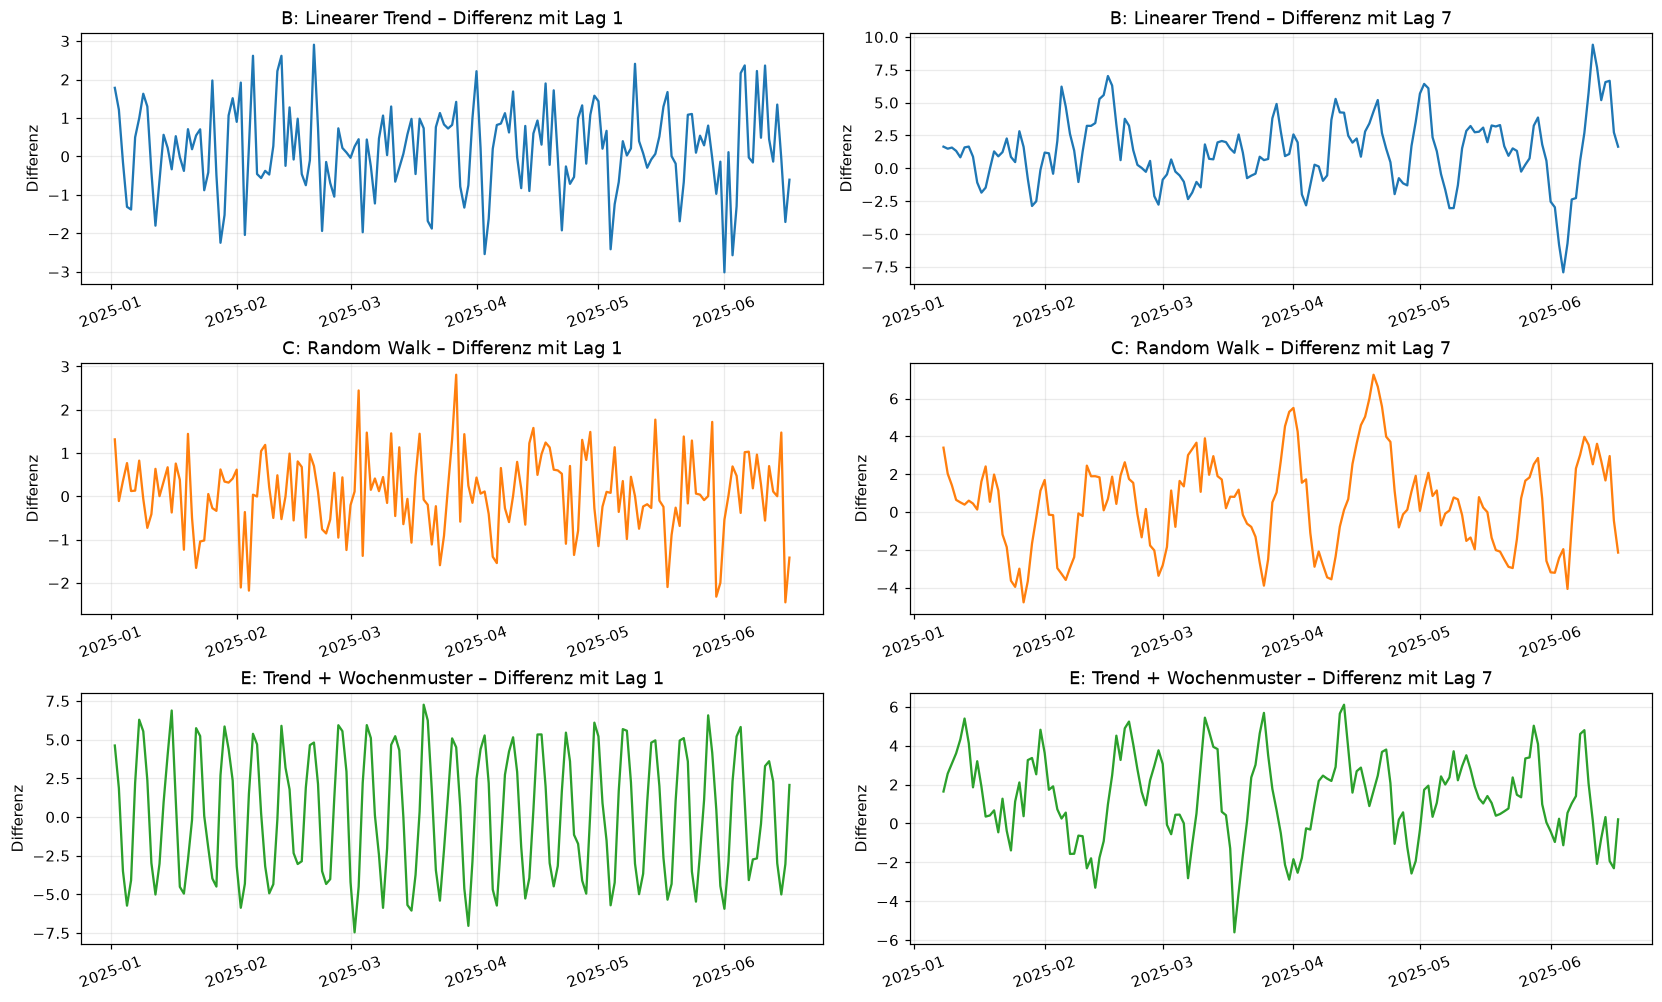

In [3]:
fig, axes = plt.subplots(3, 2, figsize=(15, 9), constrained_layout=True)
for row, name in enumerate(["B: Linearer Trend", "C: Random Walk", "E: Trend + Wochenmuster"]):
    train, _ = splits[name]  # Auch diese Betrachtung verwendet nur Trainingsdaten.
    for col, lag in enumerate([1, PERIODE]):
        axes[row, col].plot(train.diff(lag).dropna(), color=f"C{row}")
        axes[row, col].set_title(f"{name} – Differenz mit Lag {lag}")
        axes[row, col].set_ylabel("Differenz")
        axes[row, col].tick_params(axis="x", rotation=20)
plt.show()

## 4. Ein Forecast in wenigen Zeilen

`fit()` sieht ausschließlich die Trainingsdaten. `get_forecast(steps=...)` liefert Mehrschrittprognosen ohne Aktualisierung durch Testbeobachtungen. Die schattierte Fläche ist ein **modellbasiertes punktweises 95-%-Prognoseintervall** für zukünftige Beobachtungen. Es ist keine Garantie, dass 95 % eines konkreten Testverlaufs darin liegen. Die Intervalle setzen ein passendes Modell voraus und berücksichtigen die Unsicherheit geschätzter Parameter nicht vollständig.

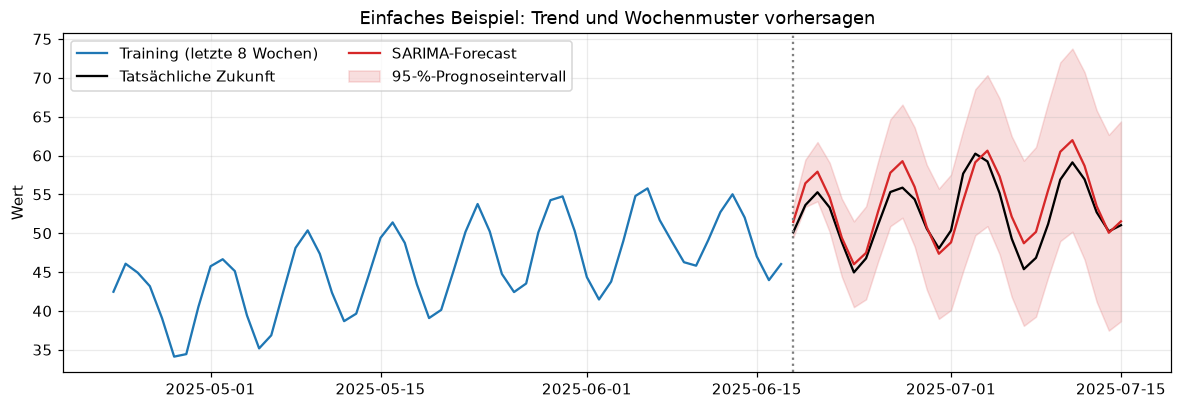

In [4]:
train, test = splits["E: Trend + Wochenmuster"]
beispiel_fit = ARIMA(train, order=(1, 1, 0),
                     seasonal_order=(0, 1, 1, PERIODE), trend="n").fit()
beispiel_forecast = beispiel_fit.get_forecast(steps=len(test))
beispiel_intervall = beispiel_forecast.conf_int(alpha=0.05)

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(train.iloc[-56:], label="Training (letzte 8 Wochen)", color="tab:blue")
ax.plot(test, label="Tatsächliche Zukunft", color="black")
ax.plot(beispiel_forecast.predicted_mean, label="SARIMA-Forecast", color="tab:red")
ax.fill_between(test.index, beispiel_intervall.iloc[:, 0], beispiel_intervall.iloc[:, 1],
                color="tab:red", alpha=0.15, label="95-%-Prognoseintervall")
ax.axvline(test.index[0], color="gray", linestyle=":")
ax.set(title="Einfaches Beispiel: Trend und Wochenmuster vorhersagen", ylabel="Wert")
ax.legend(loc="upper left", ncol=2)
plt.show()

## 5. Acht Modelle auf jede Zeitreihe anwenden

Wir verwenden bewusst dieselben Kandidaten für alle Reihen. So wird auch sichtbar, was bei unpassenden Annahmen passiert. Je zwei ARMA-, drei ARIMA- und drei SARIMA-Spezifikationen werden verglichen. Die Modellnamen nennen die Ordnungen und den Trend.

Die Spezifikation **ARIMA(1,0,1) + Zeittrend** ist technisch ein ARMA-Fehlerprozess um eine deterministische Trendgerade; sie zeigt eine Alternative zur Differenzierung. Die SARIMA-Modelle vergleichen saisonale Abhängigkeit (`P=1, D=0`) mit saisonaler Differenzierung (`D=1`). Stationaritäts- und Invertibilitätsbedingungen für die AR-/MA-Teile bleiben aktiviert.

Als Referenz dienen **Naiv** (letzten Trainingswert fortschreiben) und **Saisonal naiv** (letzte Trainingswoche wiederholen). Beide benötigen keine Parameterschätzung. Warnungen und fehlgeschlagene Fits werden protokolliert, statt unbemerkt zu verschwinden.

In [5]:
modelle = [
    dict(name="ARMA(1,0)", familie="ARMA", order=(1, 0, 0), seasonal_order=(0, 0, 0, 0), trend="c"),
    dict(name="ARMA(1,1)", familie="ARMA", order=(1, 0, 1), seasonal_order=(0, 0, 0, 0), trend="c"),
    dict(name="ARIMA(0,1,0) + Drift", familie="ARIMA", order=(0, 1, 0), seasonal_order=(0, 0, 0, 0), trend="t"),
    dict(name="ARIMA(1,1,1) + Drift", familie="ARIMA", order=(1, 1, 1), seasonal_order=(0, 0, 0, 0), trend="t"),
    dict(name="ARIMA(1,0,1) + Zeittrend", familie="ARIMA", order=(1, 0, 1), seasonal_order=(0, 0, 0, 0), trend="ct"),
    dict(name="SARIMA(1,0,0)(1,0,0)[7]", familie="SARIMA", order=(1, 0, 0), seasonal_order=(1, 0, 0, PERIODE), trend="c"),
    dict(name="SARIMA(1,0,1)(0,1,1)[7]", familie="SARIMA", order=(1, 0, 1), seasonal_order=(0, 1, 1, PERIODE), trend="n"),
    dict(name="SARIMA(1,1,0)(0,1,1)[7]", familie="SARIMA", order=(1, 1, 0), seasonal_order=(0, 1, 1, PERIODE), trend="n"),
]
display(pd.DataFrame(modelle).rename(columns={"name": "Modell", "familie": "Familie"}))

,Modell,Familie,order,seasonal_order,trend
0,"ARMA(1,0)",ARMA,"(1, 0, 0)","(0, 0, 0, 0)",c
1,"ARMA(1,1)",ARMA,"(1, 0, 1)","(0, 0, 0, 0)",c
2,"ARIMA(0,1,0) + Drift",ARIMA,"(0, 1, 0)","(0, 0, 0, 0)",t
3,"ARIMA(1,1,1) + Drift",ARIMA,"(1, 1, 1)","(0, 0, 0, 0)",t
4,"ARIMA(1,0,1) + Zeittrend",ARIMA,"(1, 0, 1)","(0, 0, 0, 0)",ct
5,"SARIMA(1,0,0)(1,0,0)[7]",SARIMA,"(1, 0, 0)","(1, 0, 0, 7)",c
6,"SARIMA(1,0,1)(0,1,1)[7]",SARIMA,"(1, 0, 1)","(0, 1, 1, 7)",n
7,"SARIMA(1,1,0)(0,1,1)[7]",SARIMA,"(1, 1, 0)","(0, 1, 1, 7)",n


In [6]:
def fehlerwerte(wahr, prognose):
    fehler = np.asarray(wahr) - np.asarray(prognose)
    return {"MAE": np.mean(np.abs(fehler)), "RMSE": np.sqrt(np.mean(fehler ** 2))}

forecasts = {}
fits = {}
zeilen = []
protokoll = []

for reihenname, (train, test) in splits.items():
    forecasts[reihenname] = {}
    for spec in modelle:
        name = spec["name"]
        try:
            with warnings.catch_warnings(record=True) as meldungen:
                warnings.simplefilter("always")
                fit = ARIMA(train, order=spec["order"],
                            seasonal_order=spec["seasonal_order"],
                            trend=spec["trend"]).fit(method_kwargs={"maxiter": 300})
                fc = fit.get_forecast(steps=len(test))
                mean = fc.predicted_mean
                intervall = fc.conf_int(alpha=0.05)
            konvergiert = bool(fit.mle_retvals.get("converged", True))
            if not (np.isfinite(mean).all() and np.isfinite(intervall.to_numpy()).all()):
                raise ValueError("Nicht-endliche Prognose oder Intervallgrenzen")
            assert mean.index.equals(test.index), "Zeitachsen passen nicht zusammen"
            fits[(reihenname, name)] = fit
            forecasts[reihenname][name] = {
                "mean": mean, "ci": intervall, "familie": spec["familie"],
                "konvergiert": konvergiert,
            }
            zeilen.append({"Zeitreihe": reihenname, "Modell": name,
                           "Familie": spec["familie"], **fehlerwerte(test, mean),
                           "Konvergiert": konvergiert})
            for meldung in meldungen:
                protokoll.append({"Zeitreihe": reihenname, "Modell": name,
                                  "Hinweis": str(meldung.message)})
            if not konvergiert:
                protokoll.append({"Zeitreihe": reihenname, "Modell": name,
                                  "Hinweis": "Nicht konvergiert: Ergebnis nur unter Vorbehalt betrachten."})
        except Exception as exc:
            protokoll.append({"Zeitreihe": reihenname, "Modell": name,
                              "Hinweis": f"Fit fehlgeschlagen: {type(exc).__name__}: {exc}"})

    baselines = {
        "Naiv": np.repeat(train.iloc[-1], len(test)),
        "Saisonal naiv": np.tile(train.iloc[-PERIODE:].to_numpy(),
                                 int(np.ceil(len(test) / PERIODE)))[:len(test)],
    }
    for name, werte in baselines.items():
        mean = pd.Series(werte, index=test.index)
        forecasts[reihenname][name] = {"mean": mean, "ci": None,
                                      "familie": "Referenz", "konvergiert": True}
        zeilen.append({"Zeitreihe": reihenname, "Modell": name, "Familie": "Referenz",
                       **fehlerwerte(test, mean), "Konvergiert": True})
    print(f"{reihenname}: {len(forecasts[reihenname]) - 2}/{len(modelle)} Modelle berechnet")

ergebnisse = pd.DataFrame(zeilen)
print(f"\n{len(fits)} Modell-Fits; {len(protokoll)} protokollierte Hinweise.")
if protokoll:
    hinweise = (pd.DataFrame(protokoll).groupby("Hinweis", sort=False)
                .agg(Anzahl=("Modell", "size"), Beispiel_Zeitreihe=("Zeitreihe", "first"),
                     Beispiel_Modell=("Modell", "first")).reset_index())
    display(hinweise)
    print("Vollständige Zuordnung aller Hinweise: Variable protokoll")

A: Stationäres ARMA: 8/8 Modelle berechnet
B: Linearer Trend: 8/8 Modelle berechnet
C: Random Walk: 8/8 Modelle berechnet
D: Wochenmuster: 8/8 Modelle berechnet
E: Trend + Wochenmuster: 8/8 Modelle berechnet
F: Stationäres saisonales AR: 8/8 Modelle berechnet

48 Modell-Fits; 49 protokollierte Hinweise.


Hinweis,Anzahl,Beispiel_Zeitreihe,Beispiel_Modell
"Setting the shape on a NumPy array has been deprecated in NumPy 2.5.\nAs an alternative, you can create a new view using np.reshape (with copy=False if needed).",48,A: Stationäres ARMA,"ARMA(1,0)"
Non-invertible starting MA parameters found. Using zeros as starting parameters.,1,E: Trend + Wochenmuster,"ARMA(1,1)"


Vollständige Zuordnung aller Hinweise: Variable protokoll


## 6. Forecasts übersichtlich vergleichen

Pro Zeitreihe erhält jede Modellfamilie ein eigenes Diagramm. Dadurch überlagern sich höchstens drei Modellprognosen; die Achsen sind innerhalb einer Zeitreihe gleich skaliert. Schwarz zeigt die tatsächlichen Testwerte, farbige Linien die Forecasts, Flächen die Prognoseintervalle. Gepunktet ist die saisonal naive Referenz. Die Familie ARIMA enthält hier auch die Variante mit deterministischem Zeittrend.

Die letzten acht Trainingswochen geben Kontext. Rechts der senkrechten Linie beginnt der Testbereich; keiner seiner Werte wurde zum Fit verwendet. Ein Stern im Modellnamen markiert einen nicht konvergierten Fit.

In [7]:
farben = dict(zip([m["name"] for m in modelle],
                   ["#0072B2", "#D55E00", "#009E73", "#CC79A7",
                    "#E69F00", "#0072B2", "#D55E00", "#009E73"]))

def plot_vergleich(reihenname):
    train, test = splits[reihenname]
    fig, axes = plt.subplots(1, 3, figsize=(19, 5), sharey=True, constrained_layout=True)
    for ax, familie in zip(axes, ["ARMA", "ARIMA", "SARIMA"]):
        ax.plot(train.iloc[-56:], color="0.55", label="Training", linewidth=1.3)
        ax.plot(test, color="black", label="Test (wahr)", linewidth=1.8)
        for name, fc in forecasts[reihenname].items():
            if fc["familie"] != familie:
                continue
            farbe = farben[name]
            markierung = " *" if not fc["konvergiert"] else ""
            ax.plot(fc["mean"], color=farbe, label=name + markierung, linewidth=1.7)
            ax.fill_between(test.index, fc["ci"].iloc[:, 0], fc["ci"].iloc[:, 1],
                            color=farbe, alpha=0.10)
        ax.plot(forecasts[reihenname]["Saisonal naiv"]["mean"], color="0.35",
                linestyle=":", label="Saisonal naiv")
        ax.axvline(test.index[0], color="gray", linestyle="--", linewidth=1)
        ax.set_title(familie)
        ax.tick_params(axis="x", rotation=35)
        ax.legend(loc="best", fontsize=8)
    axes[0].set_ylabel("Wert (gemeinsame Skala)")
    fig.suptitle(reihenname + " – 28 Tage Forecast mit 95-%-Prognoseintervallen", fontsize=14)
    plt.show()

### A: Stationäres ARMA

ARMA kann auf längere Sicht zum geschätzten Mittelwert zurückkehren. Unnötige Differenzierung kann die Unsicherheit vergrößern.

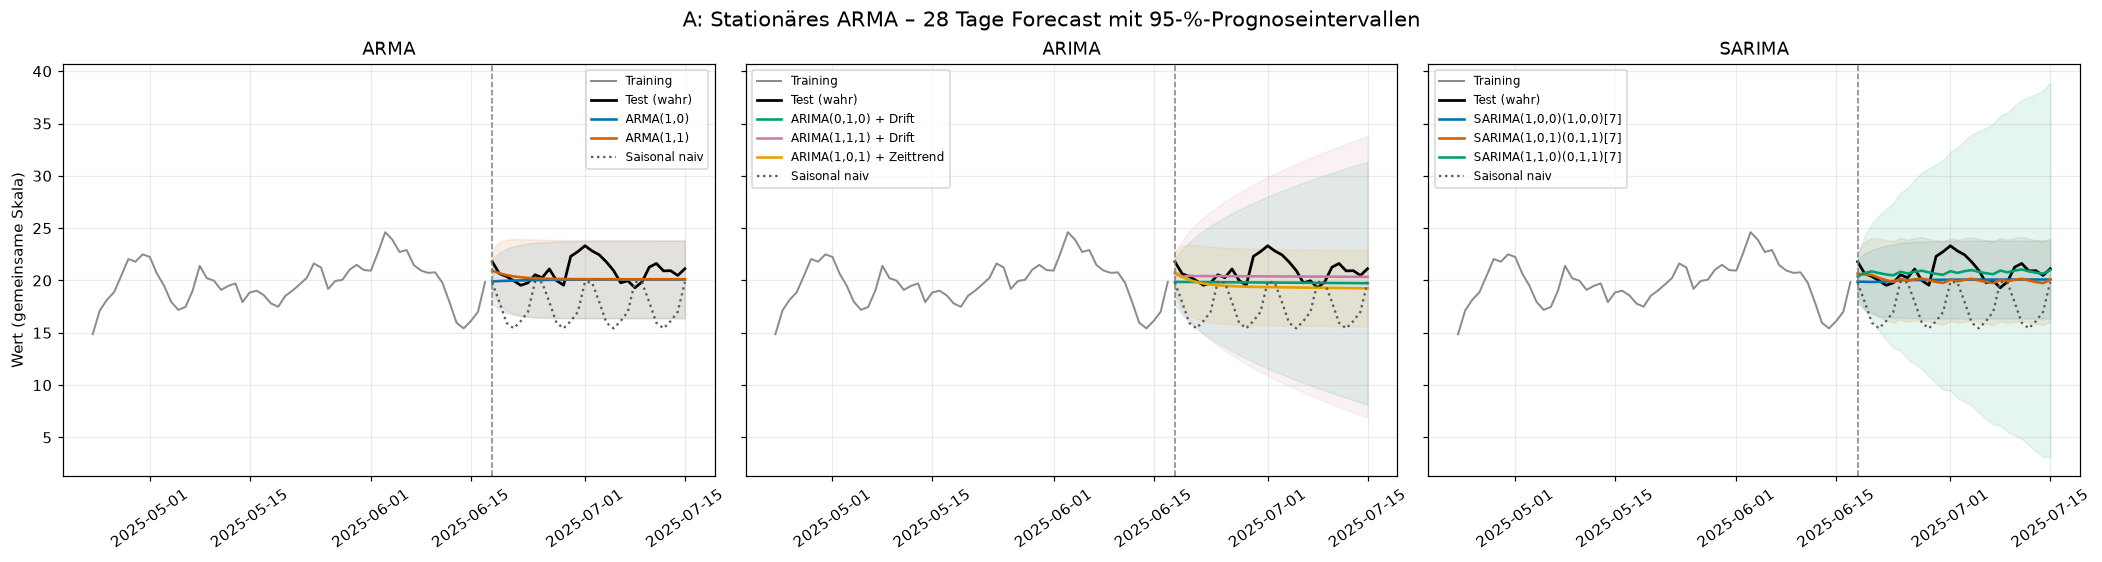

In [8]:
plot_vergleich('A: Stationäres ARMA')

### B: Linearer Trend

Ein konstanter Mittelwert passt nicht zum linearen Anstieg. Vergleichen Sie Drift, expliziten Zeittrend und saisonale Differenzierung.

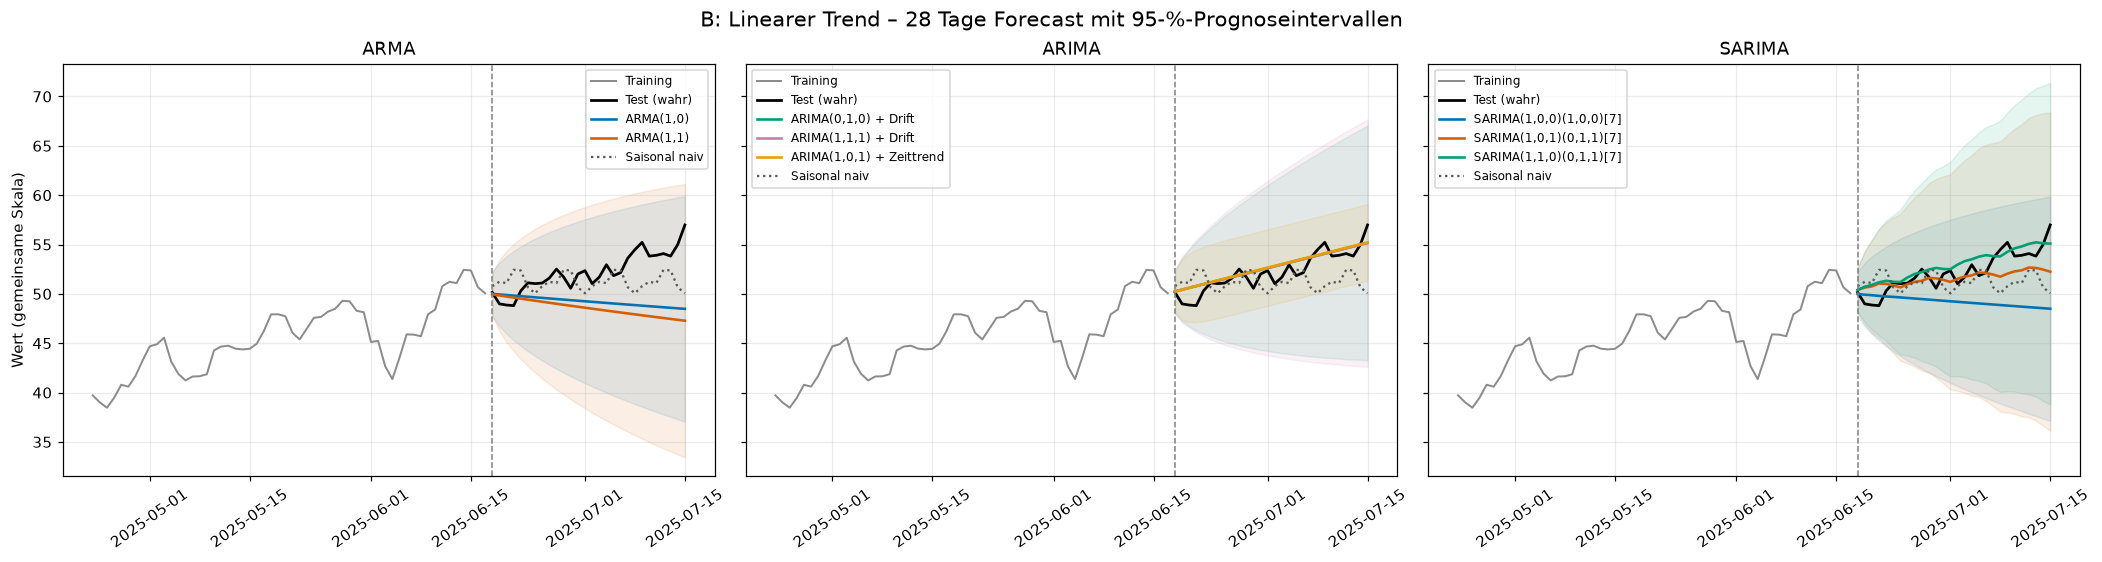

In [9]:
plot_vergleich('B: Linearer Trend')

### C: Random Walk

Die zukünftigen Innovationen sind nicht vorhersagbar. Ein geschätzter Drift kann auf diesem einzelnen Testabschnitt helfen oder schaden; Naiv ist eine wichtige Referenz.

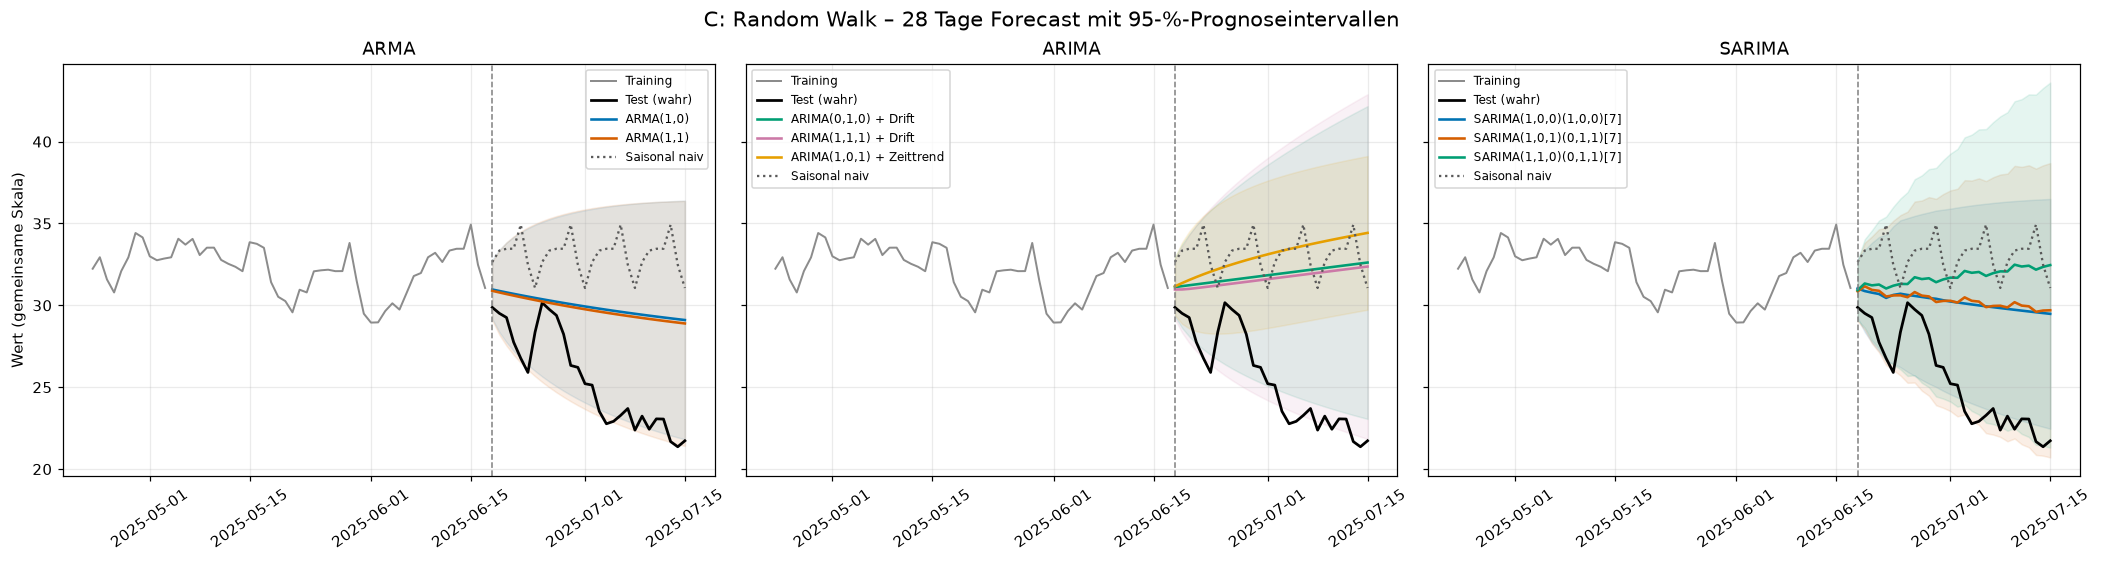

In [10]:
plot_vergleich('C: Random Walk')

### D: Wochenmuster

Saisonale Modelle können die Wochenstruktur fortsetzen. Ein Trendterm allein kann das periodische Muster nicht erklären.

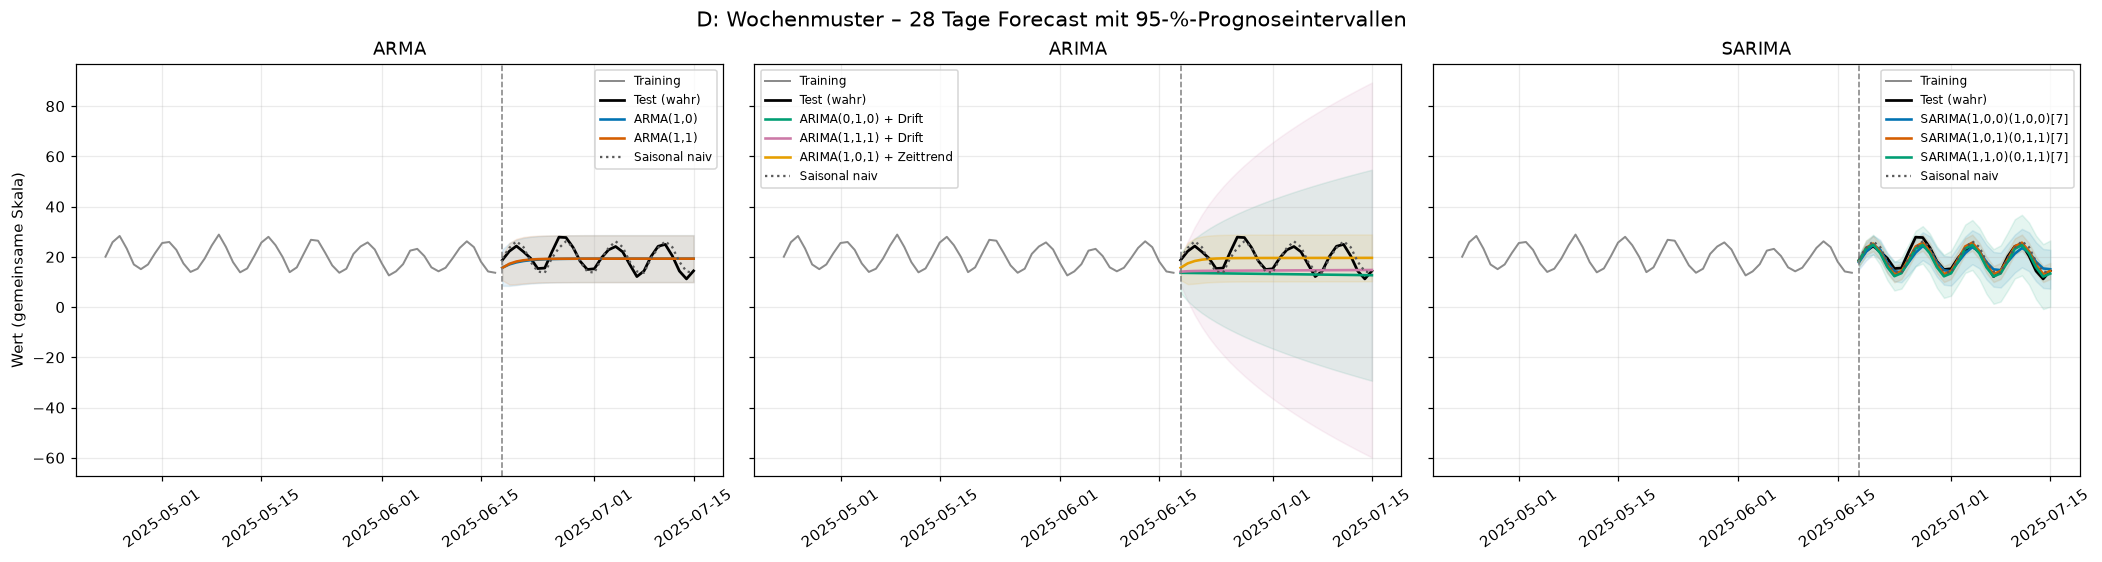

In [11]:
plot_vergleich('D: Wochenmuster')

### E: Trend + Wochenmuster

Hier sind sowohl Niveauentwicklung als auch Wochenstruktur relevant. Prüfen Sie besonders das Modell mit d=1 und D=1.

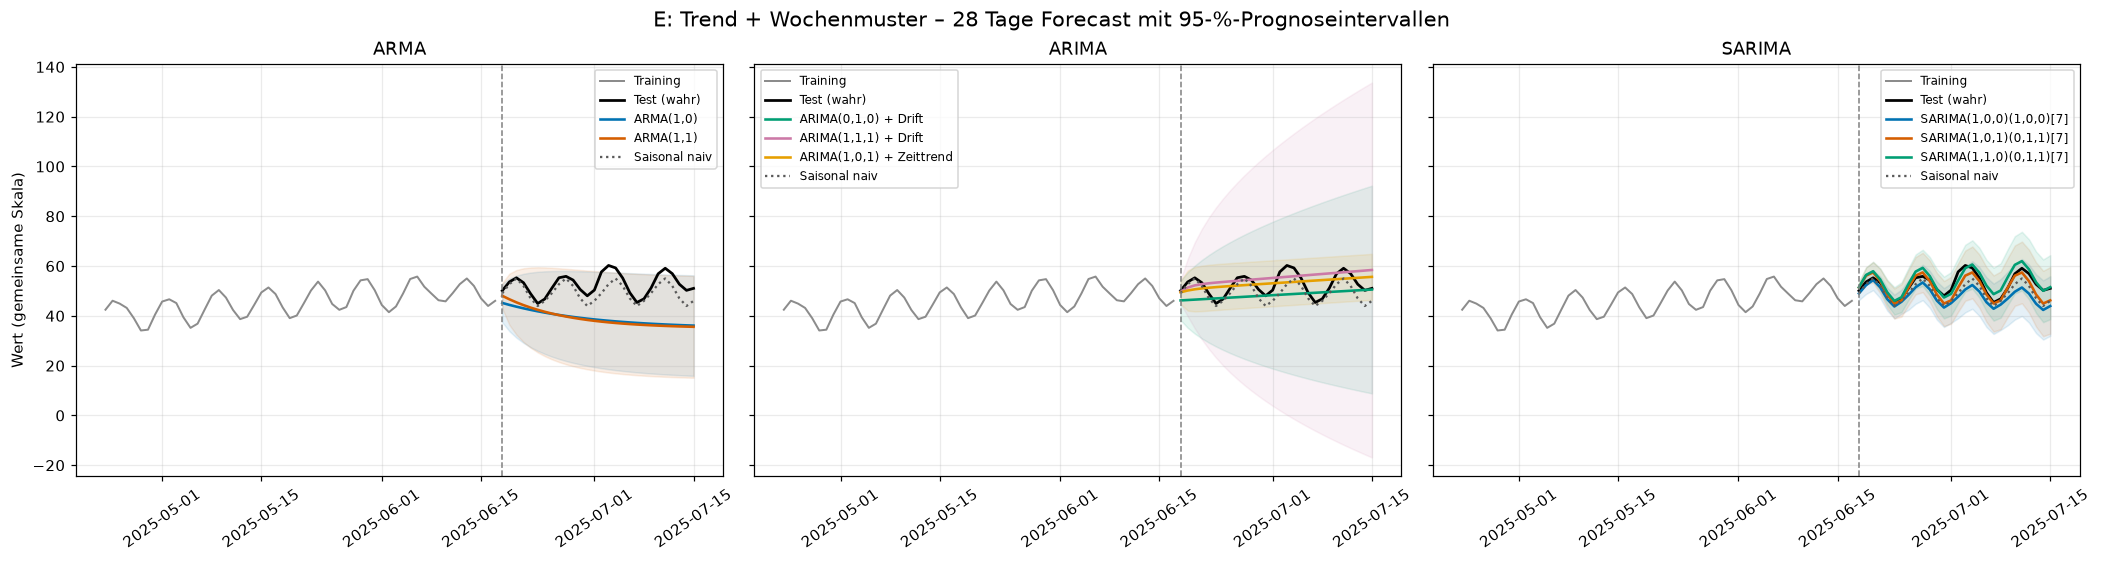

In [12]:
plot_vergleich('E: Trend + Wochenmuster')

### F: Stationäres saisonales AR

Saisonale Korrelation erfordert nicht automatisch saisonale Differenzierung. Der Prozess hat einen konstanten Mittelwert; seine Vorhersagen klingen langfristig zu diesem Niveau ab.

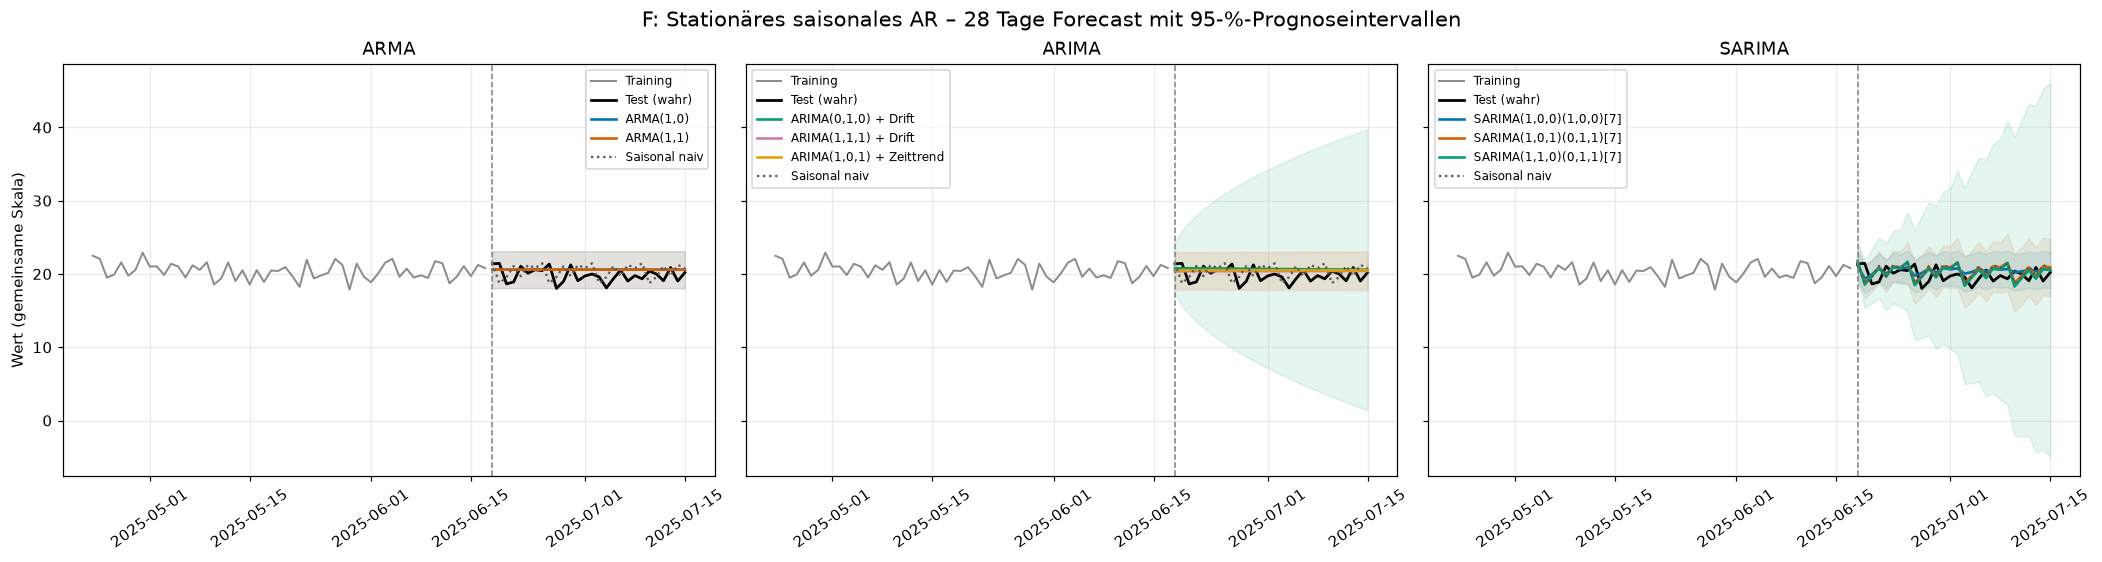

In [13]:
plot_vergleich('F: Stationäres saisonales AR')

## 7. Welche Prognose ist auf diesem Testabschnitt am besten?

**MAE** ist der mittlere absolute Fehler, **RMSE** bestraft große Abweichungen stärker. Beide stehen in der Einheit der Reihe; kleiner ist besser. Die Heatmap vergleicht die RMSE **relativ zur naiven Prognose innerhalb jeder Reihe**: unter 1 besser, über 1 schlechter. So dominieren große absolute Werte nicht die gesamte Farbdarstellung.

Wir haben die Modelle vorab festgelegt. Die folgenden Rangfolgen beschreiben diesen einen zurückgehaltenen Abschnitt. Wird anhand dieser Werte ein Modell ausgewählt, ist der Abschnitt faktisch Validierung; für eine unverzerrte Bewertung des ausgewählten Modells braucht man einen weiteren Testabschnitt oder zeitliche Kreuzvalidierung (Rolling Origin). AIC-Werte unterschiedlicher Differenzierungen werden hier nicht als gemeinsame Rangliste verwendet.

RMSE (nur konvergierte Modelle und Referenzen):
MAE:
Niedrigster RMSE auf diesem Abschnitt (einschließlich Referenzen):


Modell,"ARMA(1,0)","ARMA(1,1)","ARIMA(0,1,0) + Drift","ARIMA(1,1,1) + Drift","ARIMA(1,0,1) + Zeittrend","SARIMA(1,0,0)(1,0,0)[7]","SARIMA(1,0,1)(0,1,1)[7]","SARIMA(1,1,0)(0,1,1)[7]",Naiv,Saisonal naiv
Zeitreihe,,,,,,,,,,
A: Stationäres ARMA,1.37,1.31,1.55,1.20,1.82,1.38,1.39,1.09,1.50,3.90
B: Linearer Trend,3.82,4.54,1.02,1.02,1.03,3.81,1.64,1.23,2.91,2.54
C: Random Walk,5.09,4.93,7.21,7.00,8.47,5.36,5.49,7.10,6.31,8.19
D: Wochenmuster,4.72,4.68,7.82,6.79,4.67,2.25,1.61,1.96,7.46,1.87
E: Trend + Wochenmuster,14.35,14.60,5.90,5.17,4.32,5.31,2.61,2.24,7.73,3.77
F: Stationäres saisonales AR,1.20,1.20,1.26,1.10,1.15,1.26,1.55,1.55,1.34,1.60


Modell,"ARMA(1,0)","ARMA(1,1)","ARIMA(0,1,0) + Drift","ARIMA(1,1,1) + Drift","ARIMA(1,0,1) + Zeittrend","SARIMA(1,0,0)(1,0,0)[7]","SARIMA(1,0,1)(0,1,1)[7]","SARIMA(1,1,0)(0,1,1)[7]",Naiv,Saisonal naiv
Zeitreihe,,,,,,,,,,
A: Stationäres ARMA,1.04,0.98,1.18,0.93,1.41,1.05,1.02,0.86,1.13,3.50
B: Linearer Trend,3.19,3.81,0.80,0.80,0.82,3.19,1.23,1.00,2.40,1.98
C: Random Walk,4.48,4.32,6.40,6.17,7.58,4.74,4.85,6.30,5.60,7.59
D: Wochenmuster,4.15,4.12,6.61,5.55,4.08,1.72,1.30,1.58,6.22,1.54
E: Trend + Wochenmuster,13.33,13.35,4.80,4.14,3.83,4.55,1.96,1.92,6.61,3.11
F: Stationäres saisonales AR,0.99,0.99,1.03,0.91,0.95,1.09,1.41,1.41,1.11,1.44


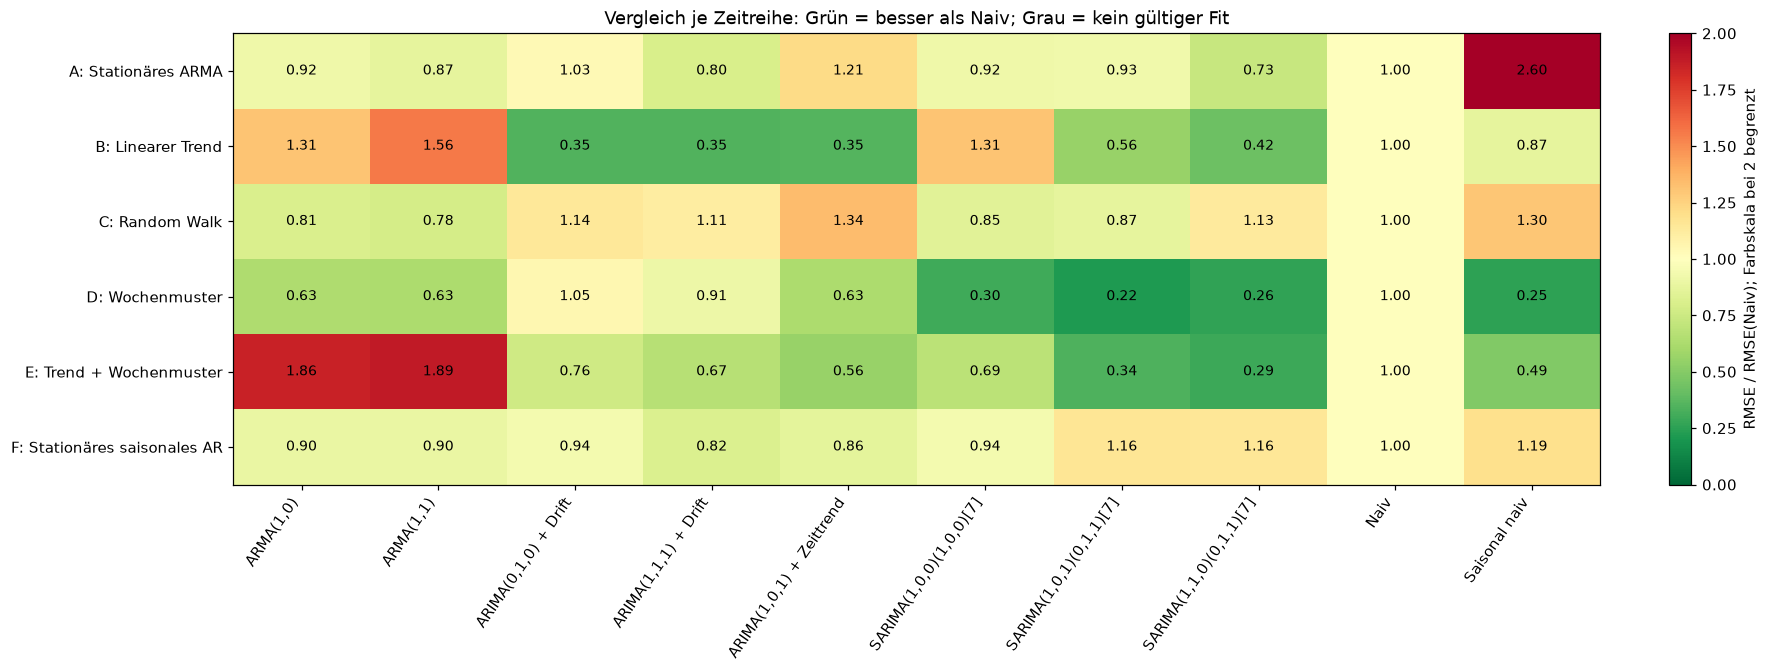

,Zeitreihe,Modell,MAE,RMSE
0,A: Stationäres ARMA,"SARIMA(1,1,0)(0,1,1)[7]",0.856,1.092
1,B: Linearer Trend,"ARIMA(1,1,1) + Drift",0.797,1.015
2,C: Random Walk,"ARMA(1,1)",4.321,4.935
3,D: Wochenmuster,"SARIMA(1,0,1)(0,1,1)[7]",1.299,1.609
4,E: Trend + Wochenmuster,"SARIMA(1,1,0)(0,1,1)[7]",1.916,2.240
5,F: Stationäres saisonales AR,"ARIMA(1,1,1) + Drift",0.912,1.098


In [14]:
gueltig = ergebnisse[ergebnisse["Konvergiert"]].copy()
reihenfolge = [m["name"] for m in modelle] + ["Naiv", "Saisonal naiv"]
rmse = gueltig.pivot(index="Zeitreihe", columns="Modell", values="RMSE").reindex(
    index=list(reihen), columns=reihenfolge)
mae = gueltig.pivot(index="Zeitreihe", columns="Modell", values="MAE").reindex(
    index=list(reihen), columns=reihenfolge)
print("RMSE (nur konvergierte Modelle und Referenzen):")
display(rmse.round(2))
print("MAE:")
display(mae.round(2))

relativ = rmse.div(rmse["Naiv"], axis=0)
fig, ax = plt.subplots(figsize=(16, 6), constrained_layout=True)
cmap = plt.get_cmap("RdYlGn_r").copy()
cmap.set_bad("lightgray")
im = ax.imshow(relativ.to_numpy(), cmap=cmap, vmin=0, vmax=2, aspect="auto")
ax.set_xticks(range(len(reihenfolge)), reihenfolge, rotation=55, ha="right")
ax.set_yticks(range(len(reihen)), list(reihen))
ax.grid(False)
for i in range(len(reihen)):
    for j in range(len(reihenfolge)):
        wert = relativ.iloc[i, j]
        ax.text(j, i, f"{wert:.2f}" if pd.notna(wert) else "–",
                ha="center", va="center", fontsize=9)
fig.colorbar(im, ax=ax, label="RMSE / RMSE(Naiv); Farbskala bei 2 begrenzt")
ax.set_title("Vergleich je Zeitreihe: Grün = besser als Naiv; Grau = kein gültiger Fit")
plt.show()

beste = gueltig.loc[gueltig.groupby("Zeitreihe")["RMSE"].idxmin()]
print("Niedrigster RMSE auf diesem Abschnitt (einschließlich Referenzen):")
display(beste[["Zeitreihe", "Modell", "MAE", "RMSE"]].reset_index(drop=True).round(3))

## 8. Was nehmen wir mit?

- **Stationäre Reihe:** ARMA ist ein sinnvoller Ausgangspunkt. Mehr Differenzierung ist nicht automatisch besser.
- **Trend:** Ein deterministischer Zeittrend und ein integrierter Prozess sind unterschiedliche Annahmen. Beide können kurzfristig ähnlich aussehen.
- **Wochenmuster:** Saisonale Terme berücksichtigen die Periode. Ob `D=1` sinnvoll ist, hängt vom Prozess ab; stationäre saisonale Abhängigkeit benötigt das nicht zwingend.
- **Zufall bleibt Zufall:** Auch bei bekannter Modellfamilie lässt sich zukünftiges Rauschen nicht vorhersagen. Ein komplexeres Modell muss eine einfache Referenz nicht schlagen.
- **Unsicherheit:** Breite Intervalle können angemessen sein. Enge Intervalle eines falsch spezifizierten Modells sind kein Qualitätsmerkmal.

### Zum Ausprobieren

1. Ändern Sie `SEED` und führen Sie ab der Datenerzeugung alle Zellen erneut aus. Bleiben die Rangfolgen gleich?
2. Verlängern Sie `HORIZONT` auf 56. Wie ändern sich Prognosen und Intervalle? Die Trainingslänge bleibt dabei gleich.
3. Erhöhen Sie die Trendsteigung oder die Amplitude der Wochenkurve. Welche Modelle profitieren relativ zu ARMA?
4. Ergänzen Sie ARIMA(0,1,0) ohne Drift (`trend="n"`). Vergleichen Sie dieses Modell auf dem Random Walk mit der naiven Referenz.
5. Für einen belastbareren Vergleich: Wiederholen Sie die Auswertung an mehreren aufeinanderfolgenden Prognosestartpunkten, jeweils nur mit zu diesem Zeitpunkt verfügbaren Trainingsdaten.

**Geltungsbereich:** Diese Beispiele verwenden additive Effekte, konstante Rauschvarianz und eine bekannte Wochenperiode. Reale Daten benötigen zusätzlich Prüfung auf fehlende Werte, Ausreißer, Strukturbrüche, variable Saisonalität sowie Residuen mit verbleibender Autokorrelation. Aus einem einzigen simulierten Verlauf folgt keine allgemeine Rangfolge der Modellfamilien.